In [1]:
import  pandas as pd 
import numpy  as np
import scipy.stats as stats

import matplotlib.pyplot as plt 
import seaborn as sns

In [2]:
from sklearn.model_selection import train_test_split 
from sklearn.metrics import accuracy_score 
from sklearn.model_selection import cross_val_score

from sklearn.linear_model import LogisticRegression
from sklearn.tree  import DecisionTreeClassifier

from sklearn.preprocessing import FunctionTransformer
from sklearn.compose import ColumnTransformer 

In [3]:
df =pd.read_csv('train(ML).csv',usecols=['Age','Fare','Survived']) 

In [4]:
df['Age'] = df['Age'].fillna(df['Age'].mean())

In [5]:
df.head()

,Survived,Age,Fare
0,0,22.0,7.2500
1,1,38.0,71.2833
2,1,26.0,7.9250
3,1,35.0,53.1000
4,0,35.0,8.0500


In [6]:
x=df.iloc[:,1:3]

In [7]:
y=df.iloc[:,0]

In [8]:
X_train,X_test,y_train,y_test=train_test_split(x,y,test_size = 0.2,random_state=42)

C:\Users\Vishal\AppData\Local\Temp\ipykernel_16408\2946980492.py:4: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(X_train['Age'])


<function matplotlib.pyplot.show(close=None, block=None)>

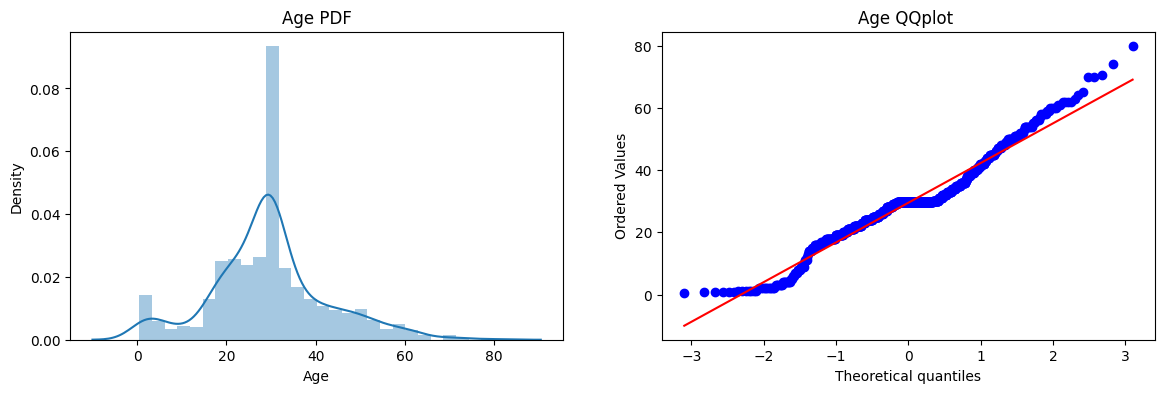

In [9]:
#now here we willcheck  Age and Fare are  normalaly distrbuted or not (PDF ,QQplot ) 
plt.figure(figsize =(14,4))
plt.subplot(121)
sns.distplot(X_train['Age'])
plt.title('Age PDF')

plt.subplot(122)
stats.probplot(X_train['Age'],dist='norm',plot=plt)
plt.title('Age QQplot ')
plt.show 

C:\Users\Vishal\AppData\Local\Temp\ipykernel_16408\2448922260.py:4: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(X_train['Fare'])


<function matplotlib.pyplot.show(close=None, block=None)>

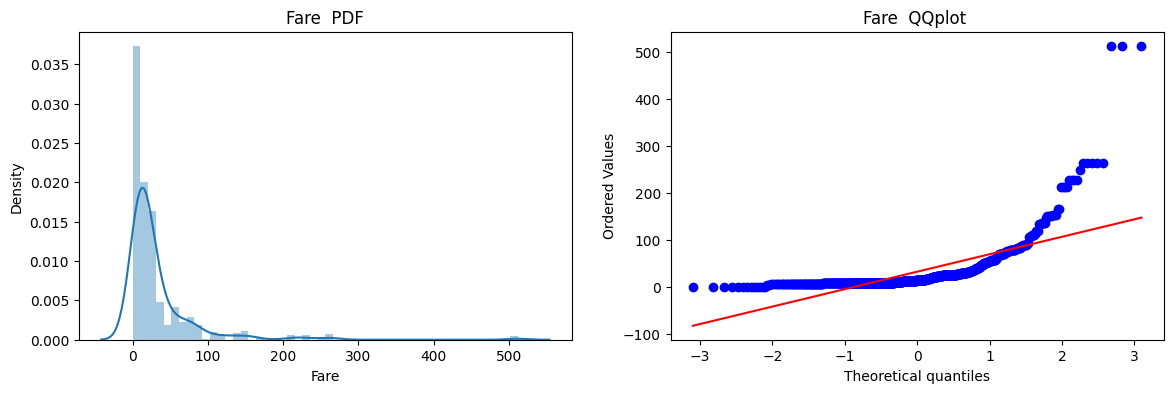

In [10]:
#now here we willcheck  Age and Fare are  normalaly distrbuted or not (PDF ,QQplot ) 
plt.figure(figsize =(14,4))
plt.subplot(121)
sns.distplot(X_train['Fare'])
plt.title('Fare  PDF')

plt.subplot(122)
stats.probplot(X_train['Fare'],dist='norm',plot=plt)
plt.title('Fare  QQplot ')
plt.show 

In [11]:
clf = LogisticRegression()
clf2 = DecisionTreeClassifier()

In [18]:
clf.fit(X_train,y_train)
clf2.fit(X_train,y_train)

y_pred =clf.predict(X_test)
y_pred2=clf.predict(X_test)

print ("accuracy score :: ",accuracy_score(y_test,y_pred))
print ("accuracy score :: ",accuracy_score(y_test,y_pred2))

accuracy score ::  0.6480446927374302
accuracy score ::  0.6480446927374302


In [23]:
trf = FunctionTransformer(func=np.log1p)
X_train_transformed = trf.fit_transform(X_train)
X_test_transformed = trf.transform(X_test)

In [24]:
clf = LogisticRegression()
clf2 = DecisionTreeClassifier()

In [25]:
clf.fit(X_train_transformed,y_train)
clf2.fit(X_train_transformed ,y_train)

y_pred =clf.predict(X_test_transformed)
y_pred2 =clf.predict(X_test_transformed)

print ("tansformed accuracy score :: ",accuracy_score(y_test,y_pred))
print ("transformed accuracy score :: ",accuracy_score(y_test,y_pred2))

tansformed accuracy score ::  0.6815642458100558
transformed accuracy score ::  0.6815642458100558


In [29]:
X_tranformed = trf.fit_transform(x)

In [30]:
clf = LogisticRegression()
clf2 = DecisionTreeClassifier()

In [34]:
print("LR",np.mean(cross_val_score(clf,X_tranformed,y,scoring ='accuracy',cv =10)))
print("DT",np.mean(cross_val_score(clf2,X_tranformed,y,scoring ='accuracy',cv =10)))

LR 0.678027465667915
DT 0.6633333333333333


<function matplotlib.pyplot.show(close=None, block=None)>

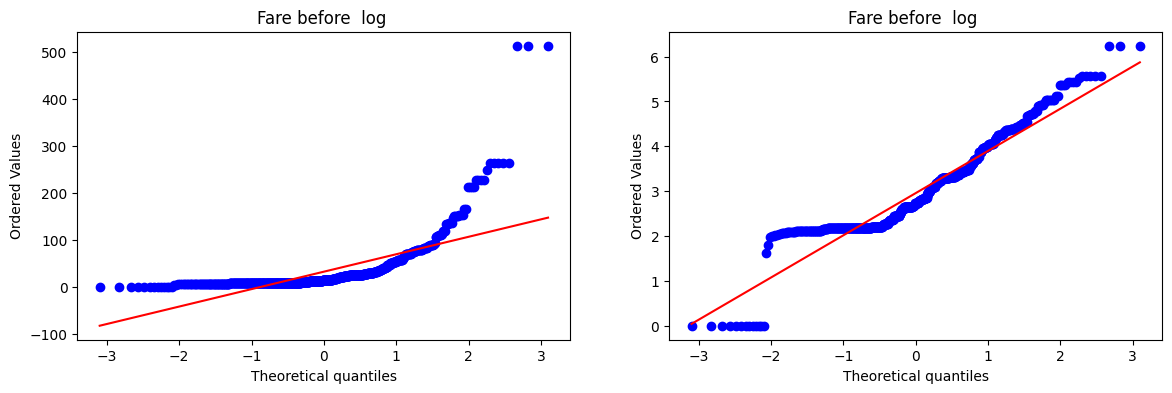

In [36]:
plt.figure(figsize =(14,4))

plt.subplot(121)
stats.probplot(X_train['Fare'],dist='norm',plot=plt)
plt.title('Fare before  log ')
plt.show 


plt.subplot(122)
stats.probplot(X_train_transformed['Fare'],dist='norm',plot=plt)
plt.title('Fare before  log ')
plt.show 

<function matplotlib.pyplot.show(close=None, block=None)>

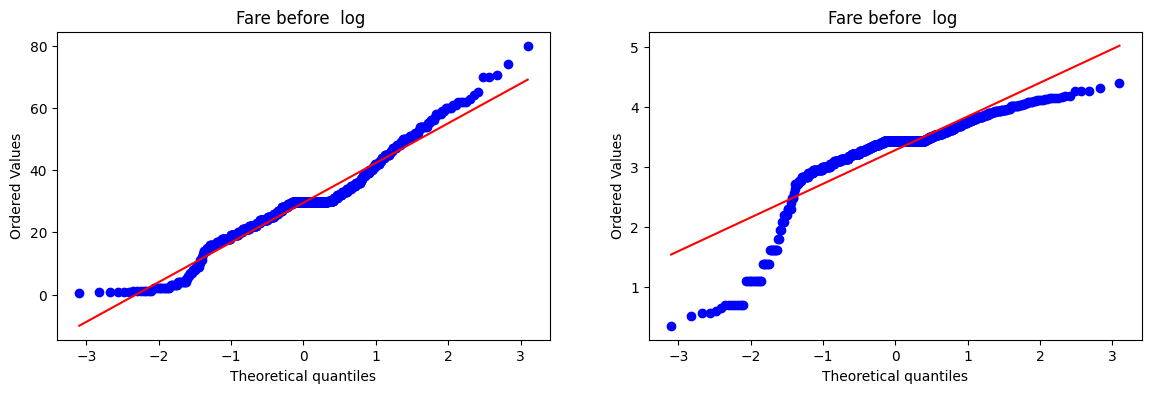

In [37]:
plt.figure(figsize =(14,4))

plt.subplot(121)
stats.probplot(X_train['Age'],dist='norm',plot=plt)
plt.title('Fare before  log ')
plt.show 


plt.subplot(122)
stats.probplot(X_train_transformed['Age'],dist='norm',plot=plt)
plt.title('Fare before  log ')
plt.show 

In [46]:
trf2 = ColumnTransformer([
    ('log',FunctionTransformer(np.log1p),['Fare'])],remainder ='passthrough')
X_train_trans2 = trf2.fit_transform(X_train)
X_test_trans2 = trf2.transform(X_test)

In [47]:
clf = LogisticRegression()
clf2 = DecisionTreeClassifier()

In [49]:
clf.fit(X_train_trans2,y_train)
clf2.fit(X_train_trans2,y_train)

y_pred =clf.predict(X_test_trans2)
y_pred2 =clf.predict(X_test_trans2)

print ("tansformed accuracy score :: ",accuracy_score(y_test,y_pred))
print ("transformed accuracy score :: ",accuracy_score(y_test,y_pred2))

tansformed accuracy score ::  0.6703910614525139
transformed accuracy score ::  0.6703910614525139


In [56]:
def apply_transform(transform):
    x=df.iloc[:,1:3]
    y=df.iloc[:,0]

    trf =ColumnTransformer ([('log',FunctionTransformer(transform),['Fare'])],remainder ='passthrough')
    X_trans=trf.fit_transform(x)
    
    clf =LogisticRegression()
    print("Accuracy ",np.mean(cross_val_score(clf,X_trans,y,scoring ='accuracy',cv=10)))
    plt.figure(figsize=(14,4))

    plt.subplot(121)
    stats.probplot(x['Fare'],dist='norm',plot=plt)
    plt.title("Fare Before transform ")

    plt.subplot(122)
    stats.probplot(X_trans[:,0],dist='norm',plot=plt)
    plt.title("Fare After  transform ")

    plt.show()

Accuracy  0.61729088639201


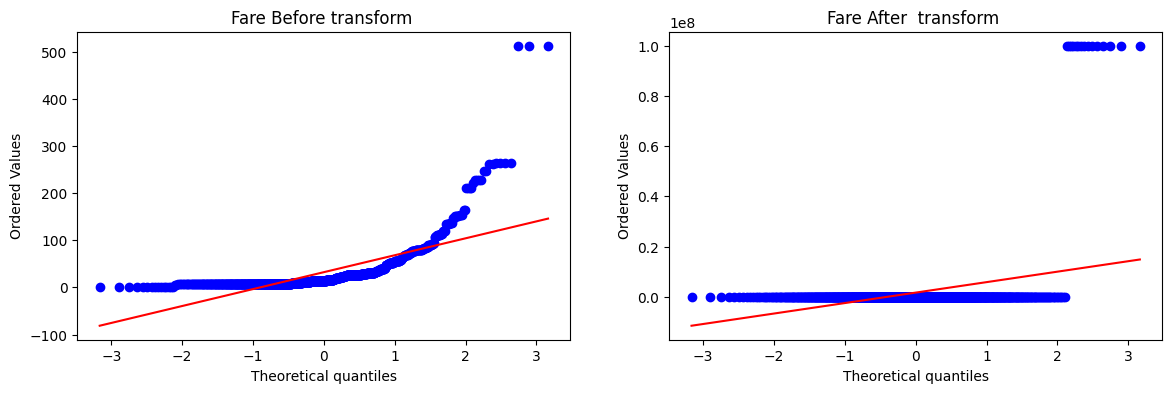

In [64]:
apply_transform(lambda x:1/(x+0.00000001))